# Mini-Project 2: Solar Micro-Grid Dispatch Planner

**Scenario.** A rural health centre in Kasese runs a micro-grid. Each day the energy drawn from solar panels ($x$) and batteries ($y$) must satisfy

$$3x + 2y = D_1 \quad\text{(daytime load, kWh)}, \qquad 4x + y = D_2 \quad\text{(critical-equipment load, kWh)}.$$

All logic lives in [`src/microgrid.py`](src/microgrid.py). Demand data are **synthetic** (seeded), and the costs are the brief's **illustrative** UGX 150/kWh (solar) and UGX 450/kWh (battery).

In [1]:
import statistics
import timeit
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.linalg

from src.microgrid import (
    HybridMicroGrid,
    MicroGrid,
    SingularSystemError,
    generate_demand_csv,
    load_demand_csv,
    prompt_demands,
)

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. The `MicroGrid` class and well-posedness

In [2]:
grid = MicroGrid()
print(grid)
print("A =\n", grid.A)
print(f"det(A)  = {grid.determinant:.4f}   (hand: 3*1 - 2*4 = -5)")
print(f"cond(A) = {grid.condition_number:.4f}")
print("singular values:", np.round(np.linalg.svd(grid.A, compute_uv=False), 4))

MicroGrid(sources=('solar', 'battery'), det=-5, cond=5.83)
A =
 [[3. 2.]
 [4. 1.]]
det(A)  = -5.0000   (hand: 3*1 - 2*4 = -5)
cond(A) = 5.8284
singular values: [5.3983 0.9262]


**Interpretation.**

* **Determinant = −5 ≠ 0.** The two constraint lines are not parallel, so every demand pair $(D_1, D_2)$ has exactly one solution. The closed form (Cramer's rule) is $x = (2D_2 - D_1)/5$ and $y = (4D_1 - 3D_2)/5$. The negative sign only means the column order flips orientation. The size of the determinant alone says little about stability, because scaling the equations changes it.
* **Condition number ≈ 5.83.** This is the ratio of the largest to the smallest singular value. It bounds how much a *relative* error in the demands can be amplified in the solution: $\frac{\|\delta x\|}{\|x\|} \le \kappa(A)\,\frac{\|\delta d\|}{\|d\|}$. A 1% metering error could therefore move the dispatch by up to about 6%. That is well-conditioned in numerical terms (we lose fewer than one significant digit of the roughly 16 in double precision). It is still large enough to matter for planning when demand forecasts are only accurate to a few percent (see the sensitivity extension).
* **Physical feasibility is a separate question.** The formulas above show that $x \ge 0$ needs $D_2 \ge D_1/2$ and $y \ge 0$ needs $D_2 \le \tfrac43 D_1$. A well-posed system can still give a negative, unusable dispatch.

In [3]:
x, y = grid.solve_day(120, 140)
print(f"solve_day(120, 140) -> solar x = {x:.2f} kWh, battery y = {y:.2f} kWh")
print(f"Cramer's rule check: x = {(2 * 140 - 120) / 5:.2f}, y = {(4 * 120 - 3 * 140) / 5:.2f}")

solve_day(120, 140) -> solar x = 32.00 kWh, battery y = 12.00 kWh
Cramer's rule check: x = 32.00, y = 12.00


## 2. Input modes

### (a) Interactive `input()` with validation

`read_non_negative_float` rejects empty, non-numeric, non-finite and negative entries, then asks again. So that *Restart & Run All* never blocks, the cell below passes a scripted sequence of keystrokes through the injectable `input_fn` argument. Set `INTERACTIVE = True` to type real values.

In [4]:
INTERACTIVE = False

if INTERACTIVE:
    demands_today = prompt_demands(grid)
else:
    scripted = iter(["", "abc", "-30", "nan", "118.5", "1,40"])  # 4 bad entries for D1, then valid D1 and D2

    def fake_input(prompt: str) -> str:
        value = next(scripted)
        print(f"{prompt}{value!r}")
        return value

    demands_today = prompt_demands(grid, input_fn=fake_input)
print("Accepted demands:", demands_today, "-> dispatch:", np.round(grid.solve_day(*demands_today), 2))

Enter D1 (kWh): ''
  Please enter a value (input was empty).
Enter D1 (kWh): 'abc'
  'abc' is not a number. Try again.
Enter D1 (kWh): '-30'
  Demand cannot be negative.
Enter D1 (kWh): 'nan'
  Value must be a finite number.
Enter D1 (kWh): '118.5'
Enter D2 (kWh): '1,40'
Accepted demands: [118.5 140. ] -> dispatch: [32.3 10.8]


Note: `"1,40"` is read as 140, because commas are stripped as thousands separators. Under that rule a typo meant as "1.40" would be accepted as 140 kWh. That is a reasonable choice for kWh values in Uganda, which use comma thousand separators, but it is worth knowing.

### (b) 30 days from a CSV file

I generate the CSV myself with a seeded generator. Weekdays are busier than weekends (outpatient clinics and the lab run Monday–Friday), and Gaussian noise is added. See the `generate_demand_csv` docstring for the exact assumptions.

In [5]:
csv_path = generate_demand_csv(Path("data") / "kasese_demand_30days.csv", days=30, seed=SEED)
demands, dates = load_demand_csv(csv_path)
demand_df = pd.read_csv(csv_path)
print(f"Loaded {len(demands)} days from {csv_path}")
display(demand_df.head(8))
display(demand_df.groupby(demand_df["weekday"].isin(["Sat", "Sun"])).agg(D1_mean=("D1_kWh", "mean"), D2_mean=("D2_kWh", "mean")).rename(index={False: "weekday", True: "weekend"}))

Loaded 30 days from data\kasese_demand_30days.csv


,day,date,weekday,D1_kWh,D2_kWh
0,1,2026-06-01,Mon,121.830,131.680
1,2,2026-06-02,Tue,124.500,147.520
2,3,2026-06-03,Wed,108.290,129.580
3,4,2026-06-04,Thu,120.770,137.470
4,5,2026-06-05,Fri,119.900,133.180
5,6,2026-06-06,Sat,100.280,126.220
6,7,2026-06-07,Sun,95.400,129.020
7,8,2026-06-08,Mon,122.810,133.130


,D1_mean,D2_mean
weekday,,
weekday,121.272,139.295
weekend,94.281,122.153


## 3. Loop vs vectorised solve, timed with `timeit`

In [6]:
loop_sol = grid.solve_loop(demands)
vec_sol = grid.solve_vectorised(demands)  # one scipy.linalg.solve with a 2x30 right-hand side
print("Max difference between methods:", np.abs(loop_sol - vec_sol).max())

N = 300
t_loop = timeit.timeit(lambda: [scipy.linalg.solve(grid.A, d) for d in demands], number=N) / N
t_vec = timeit.timeit(lambda: scipy.linalg.solve(grid.A, demands.T), number=N) / N
print(f"Python loop : {t_loop * 1e6:8.1f} µs per 30-day solve")
print(f"Vectorised  : {t_vec * 1e6:8.1f} µs per 30-day solve")
print(f"Speed-up    : {t_loop / t_vec:.1f}x")

Max difference between methods: 3.552713678800501e-15


Python loop :   1214.3 µs per 30-day solve
Vectorised  :     82.4 µs per 30-day solve
Speed-up    : 14.7x


**Comment.** Both methods give identical answers to machine precision, but the vectorised call is much faster (the exact factor depends on the machine and is printed above). The arithmetic itself is trivial: a 2×2 solve is a handful of floating-point operations. Almost all the loop's time is **overhead paid 30 times**: Python function calls, SciPy's input checks (`check_finite`, shape checks, dtype conversion) and the LAPACK call setup. The vectorised version pays that overhead once and LU-factorises $A$ once. It then back-substitutes all 30 right-hand-side columns inside compiled code. For 30 days either approach is instantaneous. For a year of 15-minute intervals (35,040 systems) the difference starts to matter.

## 4. Physically infeasible days

A day is infeasible when the exact solution needs a negative amount of energy from a source. Negative battery output would mean the battery is charging while it is supposed to supply load.

**Strategy.** In the report, a *negative* unmet value means that constraint is slightly over-supplied. For infeasible days I switch to **non-negative least squares** (`scipy.optimize.nnls`). It finds the dispatch with $x, y \ge 0$ that comes closest to meeting both constraints. The leftover gap $d - A x$ is reported as *unmet demand*, so the operator knows how much load to shed or cover from another source. I prefer this to plain clipping: clipping $y$ to 0 and keeping the original $x$ ignores that the constraints are coupled, while NNLS re-optimises $x$ given that $y = 0$.

In [7]:
result = grid.dispatch(demands)
report = pd.DataFrame({
    "date": dates,
    "D1": demands[:, 0], "D2": demands[:, 1],
    "exact x": result.exact[:, 0], "exact y": result.exact[:, 1],
    "dispatch x": result.dispatch[:, 0], "dispatch y": result.dispatch[:, 1],
    "unmet D1": result.unmet[:, 0], "unmet D2": result.unmet[:, 1],
    "infeasible": result.infeasible,
})
print(f"Infeasible days: {result.n_infeasible} of {len(demands)}")
display(report[report["infeasible"]])

Infeasible days: 3 of 30


,date,D1,D2,exact x,exact y,dispatch x,dispatch y,unmet D1,unmet D2,infeasible
6,2026-06-07,95.400,129.020,32.528,-1.092,32.091,0.000,-0.874,0.655,True
19,2026-06-20,90.050,125.200,32.070,-3.080,30.838,0.000,-2.464,1.848,True
26,2026-06-27,86.260,117.440,29.724,-1.456,29.142,0.000,-1.165,0.874,True


In [8]:
# Compare with naive clipping on the infeasible days
clipped = np.clip(result.exact, 0, None)
clip_gap = np.linalg.norm(demands - clipped @ grid.A.T, axis=1)
nnls_gap = np.linalg.norm(result.unmet, axis=1)
pd.DataFrame({"date": np.array(dates)[result.infeasible],
              "residual ‖d − Ax‖ clipping": clip_gap[result.infeasible],
              "residual ‖d − Ax‖ NNLS": nnls_gap[result.infeasible]})

,date,residual ‖d − Ax‖ clipping,residual ‖d − Ax‖ NNLS
0,2026-06-07,2.442,1.092
1,2026-06-20,6.887,3.080
2,2026-06-27,3.256,1.456


## 5. Descriptive statistics of solar and battery usage (`statistics` module)

Statistics are computed on the *dispatched* (non-negative) energy, since that is what the health centre actually draws.

In [9]:
usage_stats = {}
for i, src in enumerate(grid.sources):
    vals = result.dispatch[:, i].tolist()
    mean = statistics.mean(vals)
    usage_stats[src] = {"mean (kWh)": mean, "variance (kWh²)": statistics.variance(vals),
                        "std (kWh)": statistics.stdev(vals), "CV": statistics.stdev(vals) / mean}
usage_stats = pd.DataFrame(usage_stats).T
usage_stats

,mean (kWh),variance (kWh²),std (kWh),CV
solar,31.000,5.935,2.436,0.079
battery,10.613,42.634,6.529,0.615


**Which source is more volatile?** The **battery**, on every measure. Its standard deviation is about 2.7 times that of solar (6.5 vs 2.4 kWh). Relative to its mean it is about 8 times more volatile (CV 0.62 vs 0.08). I use the CV for the comparison because the two sources have very different mean levels. The reason is the solution $y = (4D_1 - 3D_2)/5$. It is a *difference* of two similar-sized loads, so ordinary day-to-day noise in either load produces large relative swings in $y$, which drops to zero on the infeasible days. Solar, $x = (2D_2 - D_1)/5$, follows the critical load closely. In practice the battery bank absorbs the variability, which is relevant for battery wear and sizing.

## 6. Cost model

In [10]:
cost_df = pd.DataFrame({"date": dates, "solar cost": result.dispatch[:, 0] * 150,
                        "battery cost": result.dispatch[:, 1] * 450, "daily cost (UGX)": result.daily_cost})
display(cost_df.describe().loc[["mean", "min", "max"]])
print(f"Monthly (30-day) energy cost: UGX {result.monthly_cost:,.0f}")
print(f"Share of cost from battery: {cost_df['battery cost'].sum() / result.monthly_cost:.1%} "
      f"(battery share of energy: {result.dispatch[:, 1].sum() / result.dispatch.sum():.1%})")
# Hand check for day 1
x1, y1 = result.dispatch[0]
print(f"Day 1 hand check: 150*{x1:.2f} + 450*{y1:.2f} = {150 * x1 + 450 * y1:,.0f} vs {result.daily_cost[0]:,.0f}")

,solar cost,battery cost,daily cost (UGX)
mean,"4,649.944","4,775.820","9,425.764"
min,"4,128.000",0.000,"4,371.240"
max,"5,567.100","10,903.500","15,123.000"


Monthly (30-day) energy cost: UGX 282,773
Share of cost from battery: 50.7% (battery share of energy: 25.5%)
Day 1 hand check: 150*28.31 + 450*18.46 = 12,551 vs 12,551


## 7. Stacked bar chart of daily usage with cost on a second axis

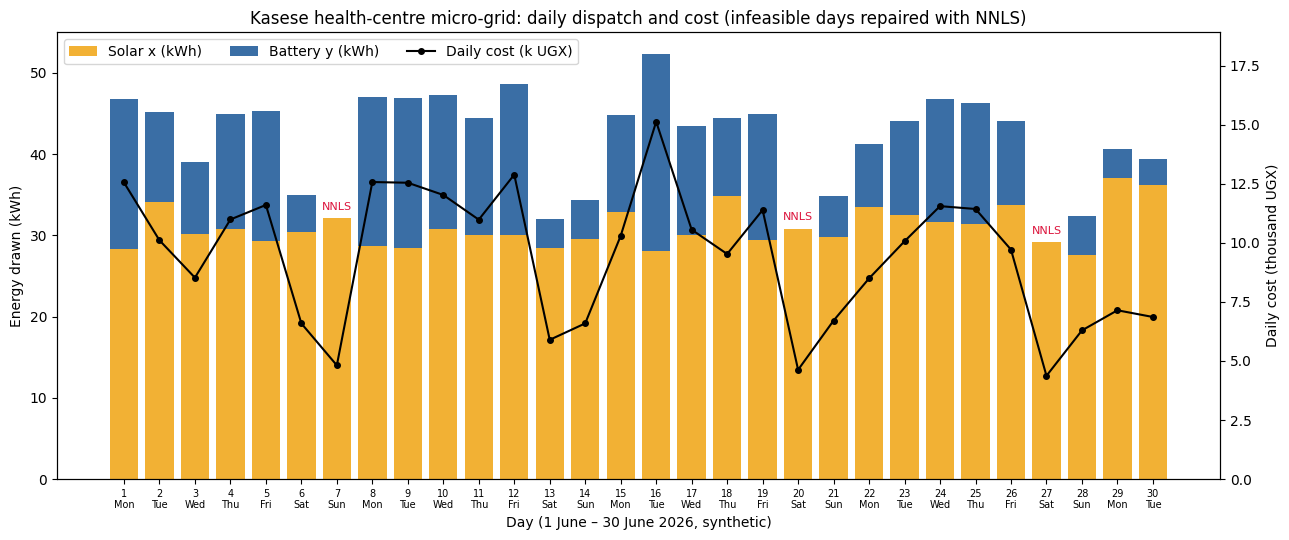

In [11]:
day_idx = np.arange(1, len(demands) + 1)
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(day_idx, result.dispatch[:, 0], color="#f2b134", label="Solar x (kWh)")
ax.bar(day_idx, result.dispatch[:, 1], bottom=result.dispatch[:, 0], color="#3a6ea5", label="Battery y (kWh)")
for d in day_idx[result.infeasible]:
    ax.annotate("NNLS", (d, result.dispatch[d - 1].sum() + 1), ha="center", fontsize=8, color="crimson")
ax.set_xlabel("Day (1 June – 30 June 2026, synthetic)")
ax.set_ylabel("Energy drawn (kWh)")
ax.set_xticks(day_idx, [f"{d}\n{w}" for d, w in zip(day_idx, demand_df["weekday"])], fontsize=7)
ax2 = ax.twinx()
ax2.plot(day_idx, result.daily_cost / 1000, "k-o", ms=4, lw=1.5, label="Daily cost (k UGX)")
ax2.set_ylabel("Daily cost (thousand UGX)")
ax2.set_ylim(0, result.daily_cost.max() / 1000 * 1.25)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", ncol=3)
ax.set_title("Kasese health-centre micro-grid: daily dispatch and cost (infeasible days repaired with NNLS)")
fig.tight_layout()
plt.show()

## Extension A: `HybridMicroGrid` with a diesel generator

`HybridMicroGrid(MicroGrid)` reuses all the solving, validation, cost and NNLS logic. It only overrides the class-level defaults: a 3×3 matrix, three unit costs (diesel at an illustrative UGX 1,200/kWh) and three source names. The third constraint I chose is the **total energy drawn over the day**, $x + y + z = D_3$, which the facility can read directly from its main meter:

$$3x + 2y + z = D_1,\quad 4x + y + 2z = D_2,\quad x + y + z = D_3.$$

For the demo I assume $D_3 \approx 0.2(D_1 + D_2)$ plus noise.

In [12]:
hybrid = HybridMicroGrid()
print(hybrid)
d3 = 0.2 * demands.sum(axis=1) + rng.normal(0, 2, size=len(demands))
hybrid_demands = np.column_stack([demands, d3])
hres = hybrid.dispatch(hybrid_demands)
print(f"Infeasible days in hybrid system: {hres.n_infeasible}")
print(f"Mean dispatch (solar, battery, diesel): {np.round(hres.dispatch.mean(axis=0), 2)} kWh")
print(f"Monthly cost: UGX {hres.monthly_cost:,.0f}")

HybridMicroGrid(sources=('solar', 'battery', 'diesel'), det=-4, cond=10.1)
Infeasible days in hybrid system: 1
Mean dispatch (solar, battery, diesel): [24.85 14.57 10.37] kWh
Monthly cost: UGX 681,998


**What if the new equation is linearly dependent on the others?** Suppose the third row were the sum of the first two, $7x + 3y + 3z = D_3$. The rows then span only a plane, so $\det A = 0$ and the condition number is infinite (in floating point, about $10^{16}$). Two things can happen:

* if $D_3 \ne D_1 + D_2$ the equations contradict each other and there is **no solution**;
* if $D_3 = D_1 + D_2$ the third equation adds no information and there are **infinitely many solutions** (a whole line of $(x, y, z)$).

Either way there is no unique dispatch. The cell below shows a subtle danger: because of floating-point round-off, `det` comes out as about $2\times10^{-15}$ rather than exactly 0. `scipy.linalg.solve` then does **not** raise an error. It only emits a `LinAlgWarning` and returns *one arbitrary point* from the infinite set of solutions (here $D_3 = D_1 + D_2$, so the system is consistent). That point even includes negative solar energy, and a slightly different $D_3$ would make the system contradictory instead. Silently accepting such an answer would be a planning error. That is why the `MicroGrid` constructor checks `matrix_rank` (which uses an SVD with a sensible tolerance) and raises `SingularSystemError` up front.

In [13]:
import warnings

dependent = np.vstack([HybridMicroGrid.DEFAULT_A[:2], HybridMicroGrid.DEFAULT_A[0] + HybridMicroGrid.DEFAULT_A[1]])
print("rank =", np.linalg.matrix_rank(dependent), " det =", np.linalg.det(dependent), " cond =", f"{np.linalg.cond(dependent):.2e}")
try:
    HybridMicroGrid(coefficients=dependent)
except SingularSystemError as err:
    print("SingularSystemError:", err)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    garbage = scipy.linalg.solve(dependent, [120.0, 140.0, 260.0])
print(f"\nscipy.linalg.solve returned {garbage} with warning: {caught[0].category.__name__ if caught else 'none'}")
print("Residual A @ x - d:", np.round(dependent @ garbage - [120, 140, 260], 6), "-> it 'solves' the equations, but so do infinitely many other x.")

rank = 2  det = 2.2204460492503135e-15  cond = 2.48e+16
SingularSystemError: coefficient matrix is singular: at least one constraint is a linear combination of the others, so there is no unique dispatch

scipy.linalg.solve returned [-1.6 34.4 56. ] with warning: LinAlgWarning
Residual A @ x - d: [0. 0. 0.] -> it 'solves' the equations, but so do infinitely many other x.


## Extension B: Monte Carlo sensitivity (±5% demand, 1,000 draws)

In [14]:
base = (120.0, 140.0)
sens = grid.sensitivity(base, n_draws=1000, pct=0.05, rng=rng)
sols = sens["solutions"]
sens_table = pd.DataFrame({
    "baseline": sens["baseline"],
    "mean": sols.mean(axis=0), "std": sols.std(axis=0, ddof=1),
    "2.5%": np.percentile(sols, 2.5, axis=0), "97.5%": np.percentile(sols, 97.5, axis=0),
}, index=["solar x", "battery y"])
sens_table["relative spread (±, 95%)"] = (sens_table["97.5%"] - sens_table["2.5%"]) / 2 / sens_table["baseline"]
display(sens_table)
amp = sens["amplification"]
print(f"Error amplification ‖δx‖/‖x‖ ÷ ‖δd‖/‖d‖: median {np.median(amp):.2f}, max {amp.max():.2f}; bound cond(A) = {sens['condition_number']:.2f}")

,baseline,mean,std,2.5%,97.5%,"relative spread (±, 95%)"
solar x,32.000,32.024,1.717,28.953,35.157,0.097
battery y,12.000,11.953,3.634,4.973,18.815,0.577


Error amplification ‖δx‖/‖x‖ ÷ ‖δd‖/‖d‖: median 4.10, max 5.83; bound cond(A) = 5.83


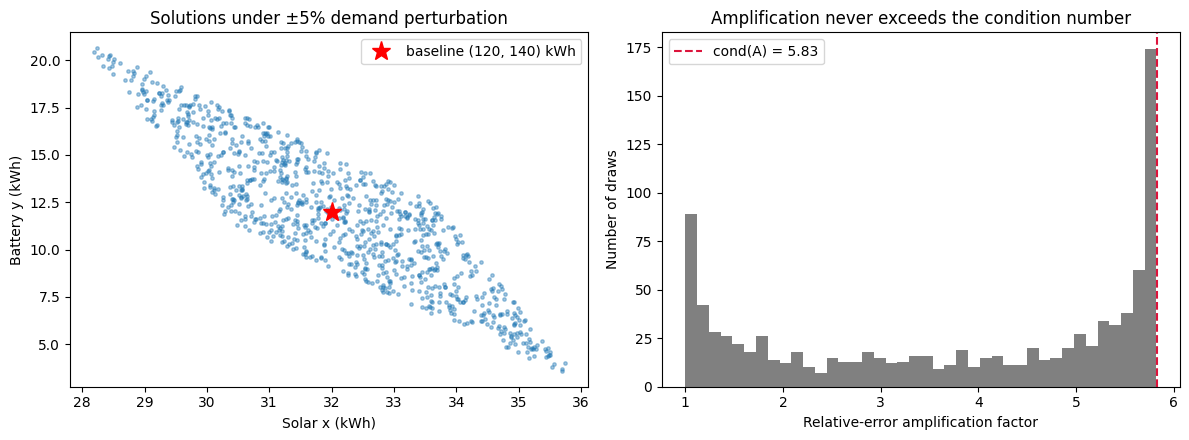

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(sols[:, 0], sols[:, 1], s=6, alpha=0.4)
axes[0].plot(*sens["baseline"], "r*", ms=14, label="baseline (120, 140) kWh")
axes[0].set_xlabel("Solar x (kWh)")
axes[0].set_ylabel("Battery y (kWh)")
axes[0].set_title("Solutions under ±5% demand perturbation")
axes[0].legend()
axes[1].hist(amp, bins=40, color="0.5")
axes[1].axvline(sens["condition_number"], color="crimson", ls="--", label=f"cond(A) = {sens['condition_number']:.2f}")
axes[1].set_xlabel("Relative-error amplification factor")
axes[1].set_ylabel("Number of draws")
axes[1].set_title("Amplification never exceeds the condition number")
axes[1].legend()
fig.tight_layout()
plt.show()

**Relation to the condition number.** A ±5% wobble in demand produces a **much larger relative swing in the battery** than in solar (see the table). That is the same cancellation effect found in Section 5. The overall amplification factor never exceeds $\kappa(A) \approx 5.83$, as theory guarantees. Many draws come close to the bound, and here is why. The amplification equals $\frac{\|\delta x\|}{\|\delta d\|}\cdot\frac{\|d\|}{\|x\|}$. At this baseline $\|d\|/\|x\| \approx 5.39 \approx \sigma_{\max}$, meaning $x$ points almost along the direction that $A$ stretches most. Any perturbation that falls along the *weakest* singular direction ($\sigma_{\min} \approx 0.93$) is then amplified by nearly the full $\sigma_{\max}/\sigma_{\min} = \kappa$. So the typical operating point of this clinic is close to the worst case for this matrix. The battery's component error (±58%) is even larger than κ × 5% because $\kappa$ bounds the error of the whole vector, and $y$ is the small component.

## Findings & Limitations

**Findings.** The dispatch system is mathematically well-posed (det = −5, κ ≈ 5.8), but that does not guarantee a physically usable answer. On 3 of the 30 synthetic days, all of them weekends, the exact solution needed *negative* battery output. Weekend daytime load falls faster than critical load, which pushes $D_2/D_1$ above 4/3. NNLS repaired those days with a residual of 1–3 kWh, less than half the gap left by naive clipping. The battery is clearly the volatile source (CV 0.62 against 0.08 for solar) because $y$ is the *difference* of two similar loads. It also drives cost: about a quarter of the energy but 51% of the UGX 283k monthly bill. Shifting flexible load into peak sun hours would therefore save the most money. The vectorised solve was an order of magnitude faster than the loop (14–20× across my runs), which only matters at much larger scale. Under ±5% demand noise, the battery's 95% range spans ±58% of its baseline, against ±10% for solar, and the amplification reached κ. Battery capacity should be sized with a generous margin.

**Limitations.** The demand data and costs are synthetic, and the two-equation model is an abstraction. Real dispatch depends on solar irradiance, battery state of charge and round-trip efficiency, none of which appear here. Each day is solved independently, so energy stored on one day cannot carry over to the next. NNLS minimises an *unweighted* residual, treating a kWh of unmet critical load like a kWh of daytime load. For a health centre, a formulation that never sheds critical load (a constrained linear programme) would be more appropriate. The diesel constraint and the UGX 1,200/kWh diesel cost are my own assumptions.